# Dense Neural Network dengan TensorFlow (Google Colab)

**Kasus:** Klasifikasi kondisi motor listrik (NORMAL vs FAULT) dari 6 fitur sensor.  
**Tujuan:** membaca CSV, eksplorasi, preprocessing, membangun Dense Network, melatih, mengevaluasi, dan memprediksi data sensor baru.

Dataset **sintetik**, 1.800 sampel, tanpa missing values atau data invalid. Label **bukan hasil diagnosis lapangan**. Kelas dirancang memiliki tumpang tindih sehingga akurasi tidak otomatis 100%.

> **Catatan:** Setiap baris merupakan satu pengamatan kondisi operasi (*snapshot*), bukan urutan waktu. Karena itu Dense sesuai untuk latihan awal; jangan memakai LSTM pada dataset ini tanpa data temporal sebenarnya.

## 0. Persiapan Colab
1. Buka https://colab.research.google.com lalu buat notebook baru.
2. Jalankan sel berikut. Umumnya TensorFlow telah tersedia di Colab.
3. Unggah file `Mission_06_Motor_Condition_Synthetic.csv` ketika diminta.

**Diskusi:** Google Colab menjalankan kode Python di lingkungan cloud; notebook terdiri dari sel teks dan sel kode.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf


print('TensorFlow:', tf.__version__)

file_name = '/content/drive/MyDrive/Colab Notebooks/MACHINE_LEARNING_2026/Motor_Condition_Data.csv'


TensorFlow: 2.21.0


## 1. Membaca dataset
Kita mulai dari membaca CSV dan mengenali struktur data. `sample_id` hanya identitas rekaman, **bukan fitur prediksi**.

In [5]:
df = pd.read_csv(file_name)
print('Ukuran data:', df.shape)
display(df.head(8))
print('Nama kolom:', df.columns.tolist())

Ukuran data: (1800, 8)


,sample_id,voltage_v,current_a,temperature_c,vibration_mm_s,rpm,load_pct,condition
0,MTR-0595,213.14,8.737,85.44,5.253,1216.8,98.0,FAULT
1,MTR-0749,215.79,5.484,54.92,2.888,1335.4,61.3,NORMAL
2,MTR-1037,217.05,6.029,63.30,3.200,1320.9,73.9,NORMAL
3,MTR-0469,223.23,5.061,60.53,1.941,1299.1,63.5,NORMAL
4,MTR-0589,217.57,5.517,61.21,2.267,1341.3,65.3,NORMAL
5,MTR-1595,220.22,3.619,48.73,1.030,1428.1,48.7,NORMAL
6,MTR-0066,222.78,5.858,71.07,5.074,1273.8,66.0,FAULT
7,MTR-1411,220.99,5.717,61.29,2.401,1267.2,87.2,NORMAL


Nama kolom: ['sample_id', 'voltage_v', 'current_a', 'temperature_c', 'vibration_mm_s', 'rpm', 'load_pct', 'condition']


## 2. Eksplorasi Data (EDA)
Periksa tipe data, sebaran kelas, rentang sensor, dan hubungan antarfitur. Karena dataset bersih, tahap ini tetap penting sebagai verifikasi kualitas.

In [6]:
df.info()
display(df.describe(include='all').T)
print('Missing values per kolom:')
print(df.isna().sum())
print('Duplikasi sample_id:', df['sample_id'].duplicated().sum())
print('Distribusi kelas:')
print(df['condition'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sample_id       1800 non-null   object 
 1   voltage_v       1800 non-null   float64
 2   current_a       1800 non-null   float64
 3   temperature_c   1800 non-null   float64
 4   vibration_mm_s  1800 non-null   float64
 5   rpm             1800 non-null   float64
 6   load_pct        1800 non-null   float64
 7   condition       1800 non-null   object 
dtypes: float64(6), object(2)
memory usage: 112.6+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sample_id,1800,1800,MTR-0902,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
voltage_v,1800.0,NaN,NaN,NaN,219.902817,7.24349,196.83,215.19,220.02,224.7525,242.55
current_a,1800.0,NaN,NaN,NaN,4.878192,1.133121,1.125,4.11125,4.8555,5.6005,8.737
temperature_c,1800.0,NaN,NaN,NaN,56.555494,9.767519,25.0,50.19,56.215,62.9225,85.44
vibration_mm_s,1800.0,NaN,NaN,NaN,2.766314,1.288816,0.15,1.8135,2.654,3.61725,6.775
rpm,1800.0,NaN,NaN,NaN,1343.965333,47.546897,1181.3,1311.975,1344.5,1377.025,1480.2
load_pct,1800.0,NaN,NaN,NaN,58.115278,18.266996,15.0,45.8,58.1,70.3,98.0
condition,1800,2,NORMAL,1160,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values per kolom:
sample_id         0
voltage_v         0
current_a         0
temperature_c     0
vibration_mm_s    0
rpm               0
load_pct          0
condition         0
dtype: int64
Duplikasi sample_id: 0
Distribusi kelas:
condition
NORMAL    1160
FAULT      640
Name: count, dtype: int64


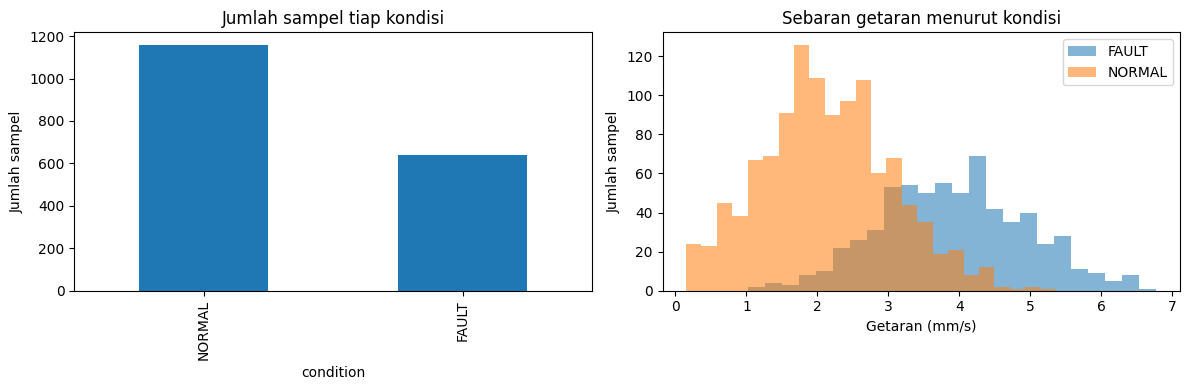

,voltage_v,current_a,temperature_c,vibration_mm_s,rpm,load_pct
voltage_v,1.00,-0.01,-0.01,-0.01,0.04,-0.01
current_a,-0.01,1.00,0.84,0.43,-0.78,0.88
temperature_c,-0.01,0.84,1.00,0.55,-0.82,0.81
vibration_mm_s,-0.01,0.43,0.55,1.00,-0.59,0.25
rpm,0.04,-0.78,-0.82,-0.59,1.00,-0.71
load_pct,-0.01,0.88,0.81,0.25,-0.71,1.00


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['condition'].value_counts().plot(kind='bar', ax=axes[0], title='Jumlah sampel tiap kondisi')
axes[0].set_ylabel('Jumlah sampel')
for label, group in df.groupby('condition'):
    axes[1].hist(group['vibration_mm_s'], bins=24, alpha=0.55, label=label)
axes[1].set_title('Sebaran getaran menurut kondisi')
axes[1].set_xlabel('Getaran (mm/s)')
axes[1].set_ylabel('Jumlah sampel')
axes[1].legend()
plt.tight_layout()
plt.show()

features = ['voltage_v', 'current_a', 'temperature_c', 'vibration_mm_s', 'rpm', 'load_pct']
display(df[features].corr().round(2))

## 3. Preprocessing
- Target: `NORMAL = 0`, `FAULT = 1` (kita yang menentukan positive class).
- Gunakan **stratified train/validation/test split** (70% / 15% / 15%).
- **Scaling hanya di-fit menggunakan training set**, untuk mencegah *data leakage*.
- Tidak ada imputasi data karena dataset ini sengaja bersih.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[features].copy()
y = df['condition'].map({'NORMAL': 0, 'FAULT': 1}).astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print('Train:', X_train_scaled.shape, 'Validation:', X_val_scaled.shape, 'Test:', X_test_scaled.shape)
print('Rata-rata train setelah scaling:', X_train_scaled.mean(axis=0).round(2))

Train: (1260, 6) Validation: (270, 6) Test: (270, 6)
Rata-rata train setelah scaling: [ 0. -0.  0. -0. -0.  0.]


## 4. Membuat model Dense
Model ini mempunyai 6 input, dua hidden layer (16 dan 8 neuron), dan satu neuron output sigmoid untuk klasifikasi biner. `binary_crossentropy` sesuai untuk target 0/1.

**Pertanyaan:** Mengapa output hanya satu neuron, tetapi kita mempunyai dua kelas?

In [ ]:
tf.keras.utils.set_random_seed(42)
model = tf.keras.Sequential([
    tf.keras.Input(shape=(len(features),)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.summary()

## 5. Training
Gunakan *training set* untuk memperbarui bobot dan *validation set* untuk memantau generalisasi setiap epoch. Model **tidak boleh dilatih menggunakan test set**.

In [ ]:
history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=35, batch_size=32, verbose=1
)

In [ ]:
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hist[['loss', 'val_loss']].plot(ax=axes[0], title='Training dan Validation Loss')
hist[['accuracy', 'val_accuracy']].plot(ax=axes[1], title='Training dan Validation Accuracy')
axes[0].set_xlabel('Epoch'); axes[1].set_xlabel('Epoch')
plt.tight_layout(); plt.show()

## 6. Evaluasi pada test set
Test set digunakan untuk evaluasi akhir. Bandingkan confusion matrix, precision, recall, dan F1-score, bukan hanya accuracy.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

loss, acc = model.evaluate(X_test_scaled, y_test, verbose=0)
proba = model.predict(X_test_scaled, verbose=0).ravel()
pred = (proba >= 0.5).astype(int)
print(f'Test loss: {loss:.4f} | Test accuracy: {acc:.2%}')
print(classification_report(y_test, pred, target_names=['NORMAL', 'FAULT'], digits=3))
cm = confusion_matrix(y_test, pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['NORMAL', 'FAULT']).plot(cmap='Blues')
plt.show()

## 7. Prediksi sampel baru
Semua nilai fitur harus mengikuti urutan `features` yang sama. Terapkan **scaler training yang sama**. Contoh hanya simulasi, bukan saran diagnosis industri.

In [ ]:
new_samples = pd.DataFrame([
    {'voltage_v': 220, 'current_a': 4.0, 'temperature_c': 51, 'vibration_mm_s': 1.2, 'rpm': 1370, 'load_pct': 50},
    {'voltage_v': 216, 'current_a': 6.4, 'temperature_c': 81, 'vibration_mm_s': 5.5, 'rpm': 1210, 'load_pct': 74},
])[features]

new_scaled = scaler.transform(new_samples)
new_probability = model.predict(new_scaled, verbose=0).ravel()
output = new_samples.copy()
output['probability_fault'] = new_probability.round(3)
output['prediction'] = np.where(new_probability >= 0.5, 'FAULT', 'NORMAL')
display(output)

## 8. Eksperimen mandiri (diskusi)
1. Ubah jumlah neuron hidden layer pertama dari **16** menjadi **4** dan **32**. Apakah akurasi test selalu membaik? **Buat ulang model dan lakukan training dari awal** untuk perbandingan yang adil.
2. Ubah epoch dari **35** menjadi **80**. Bagaimana perubahan kurva loss train vs validation? Apakah terjadi overfitting?
3. Apa yang terjadi jika `StandardScaler` dihilangkan? Bandingkan dengan kontrol eksperimen yang sama dan jelaskan alasannya.

**Materi lanjutan:** CNN dan LSTM memerlukan struktur data yang berbeda; dalam Mission ini kita fokus pada Dense saja.